# Klasifikasi Kelayakan Air Minum Berdasarkan Parameter Fisik dan Kimia Menggunakan Algoritma Decision Tree
**Lanjutan TP-05** — Muhamad Rafli Ardiansyah (301240028) — Kelas 5B

Dataset: [Water Potability (Kaggle)](https://www.kaggle.com/datasets/adityakadiwal/water-potability)  
Target (Y): `Potability` (0 = Tidak Layak Minum, 1 = Layak Minum)

## 1. Muat Dataset

In [1]:
import json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

df = pd.read_csv("../data/water_potability.csv")
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.080795,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000
Hardness,3276.0,196.369496,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000
Solids,3276.0,22014.092526,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008
Chloramines,3276.0,7.122277,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000
Sulfate,2495.0,333.775777,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642
Conductivity,3276.0,426.205111,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620
Organic_carbon,3276.0,14.284970,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000
Trihalomethanes,3114.0,66.396293,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000
Turbidity,3276.0,3.966786,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000
Potability,3276.0,0.390110,0.487849,0.000000,0.000000,0.000000,1.000000,1.000000


## 2. Exploratory Data Analysis (EDA)

### 2.1 Distribusi Kelas Target

Potability
0    1998
1    1278
Name: count, dtype: int64 

Potability
0    60.99 %
1    39.01 %
Name: count, dtype: str


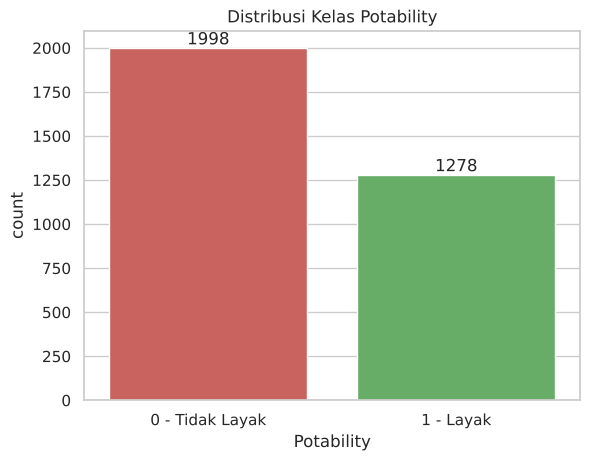

In [4]:
counts = df["Potability"].value_counts().sort_index()
print(counts, "\n")
print((counts / len(df) * 100).round(2).astype(str) + " %")

ax = sns.countplot(x="Potability", data=df, palette=["#d9534f", "#5cb85c"], hue="Potability", legend=False)
ax.set_xticks([0, 1]); ax.set_xticklabels(["0 - Tidak Layak", "1 - Layak"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.title("Distribusi Kelas Potability")
plt.savefig("../images/01_distribusi_target.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.2 Missing Values

                 jumlah_missing  persen
ph                          491   14.99
Sulfate                     781   23.84
Trihalomethanes             162    4.95


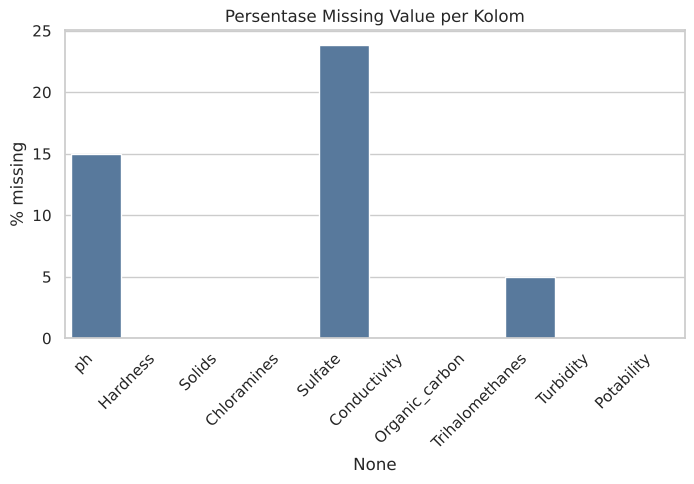

In [5]:
missing = df.isna().sum().to_frame("jumlah_missing")
missing["persen"] = (missing["jumlah_missing"] / len(df) * 100).round(2)
print(missing[missing.jumlah_missing > 0])

plt.figure(figsize=(8, 4))
sns.barplot(x=missing.index, y=missing["persen"], color="#4C78A8")
plt.xticks(rotation=45, ha="right"); plt.ylabel("% missing"); plt.title("Persentase Missing Value per Kolom")
plt.savefig("../images/02_missing_values.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.3 Distribusi Fitur Berdasarkan Target

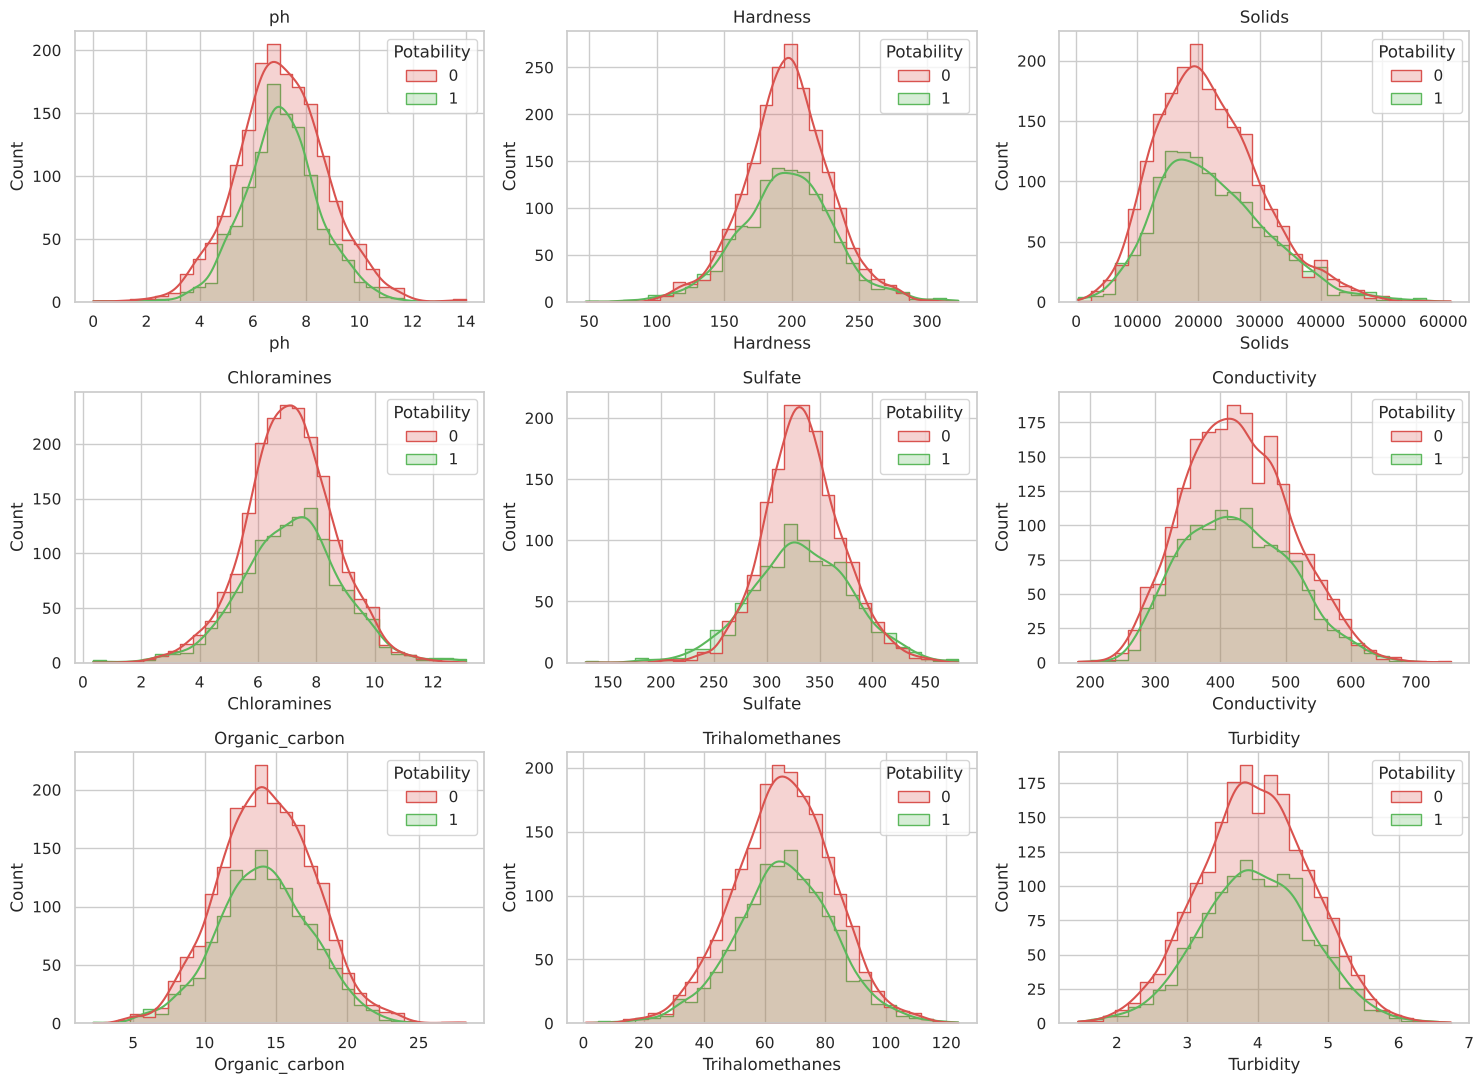

In [6]:
features = [c for c in df.columns if c != "Potability"]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df, x=col, hue="Potability", kde=True, bins=30, ax=ax,
                 palette={0: "#d9534f", 1: "#5cb85c"}, element="step")
    ax.set_title(col)
plt.tight_layout()
plt.savefig("../images/03_distribusi_fitur.png", dpi=150, bbox_inches="tight")
plt.show()

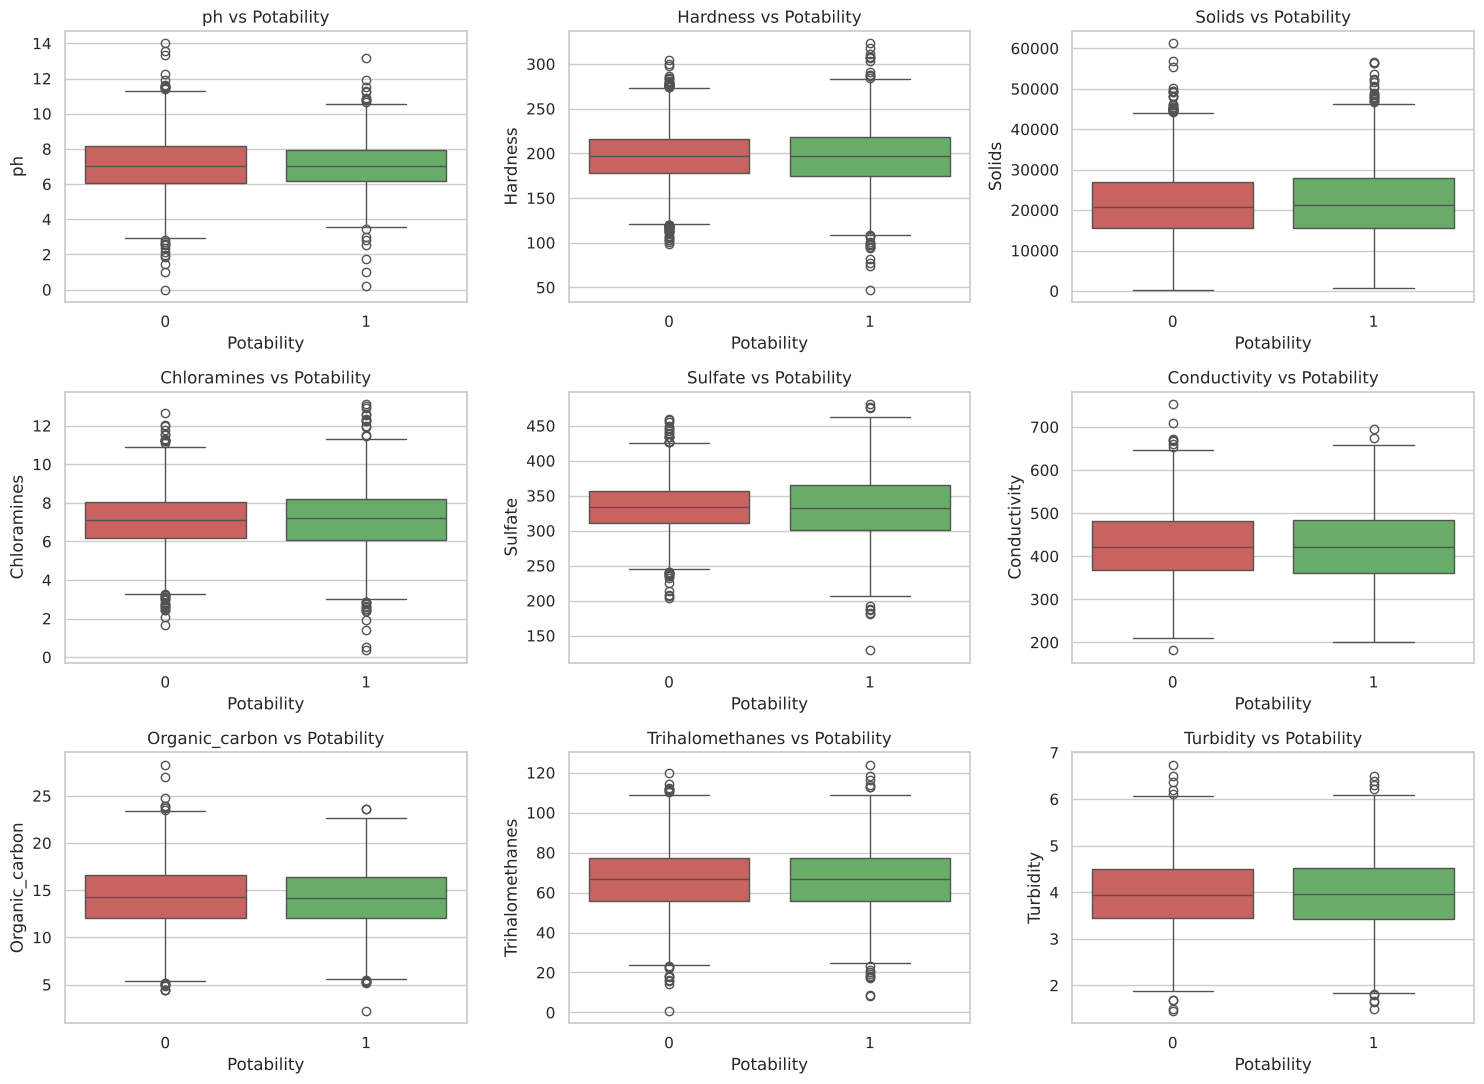

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="Potability", y=col, ax=ax, hue="Potability",
                palette={0: "#d9534f", 1: "#5cb85c"}, legend=False)
    ax.set_title(f"{col} vs Potability")
plt.tight_layout()
plt.savefig("../images/04_boxplot_fitur_vs_target.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
print(df.groupby("Potability")[features].mean().round(3).T)

Potability               0          1
ph                   7.085      7.074
Hardness           196.733    195.801
Solids           21777.491  22383.991
Chloramines          7.092      7.169
Sulfate            334.564    332.567
Conductivity       426.730    425.384
Organic_carbon      14.364     14.161
Trihalomethanes     66.304     66.540
Turbidity            3.966      3.968


### 2.4 Korelasi Antar Fitur dan Dengan Target

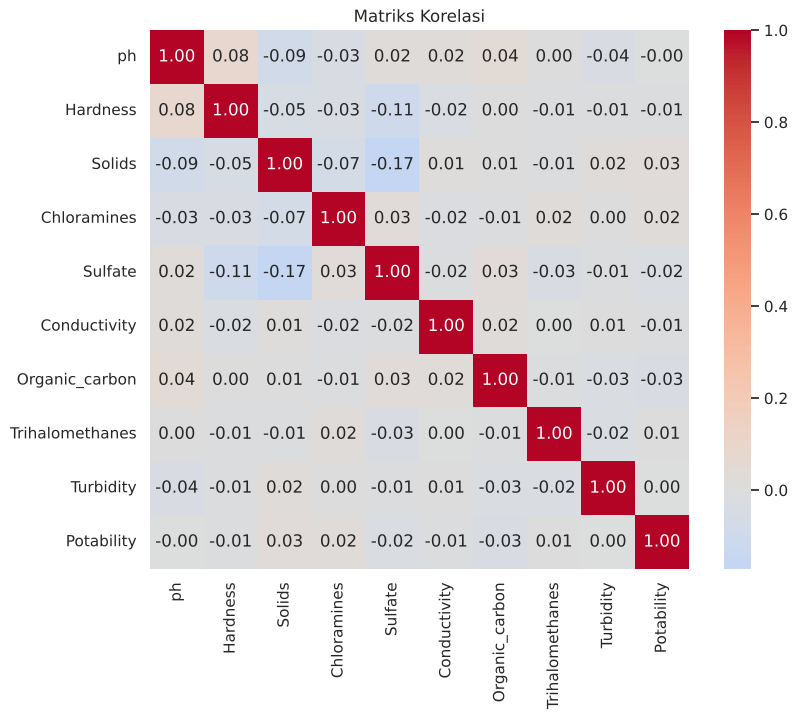

Solids             0.0337
Organic_carbon    -0.0300
Chloramines        0.0238
Sulfate           -0.0236
Hardness          -0.0138
Conductivity      -0.0081
Trihalomethanes    0.0071
ph                -0.0036
Turbidity          0.0016
Name: Potability, dtype: float64


In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriks Korelasi")
plt.savefig("../images/05_korelasi.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.corr()["Potability"].drop("Potability").sort_values(key=abs, ascending=False).round(4))

## 3. Pra-pemrosesan Data
Urutan yang dipakai: **cek fitur kategorikal → split train/test → imputasi median (dihitung dari data latih saja)**.  
Imputasi dilakukan setelah split agar tidak terjadi *data leakage* dari data uji.

### 3.1 Fitur Kategorikal

In [10]:
cat_cols = df.drop(columns="Potability").select_dtypes(exclude=[np.number]).columns.tolist()
print("Kolom non-numerik:", cat_cols if cat_cols else "tidak ada (semua fitur numerik)")

X = df.drop(columns="Potability")
y = df["Potability"]

# Jika ada kolom kategorikal, ubah dengan One-Hot Encoding. Pada dataset ini tidak ada,
# sehingga langkah ini tidak mengubah apa pun, tetapi tetap disertakan agar pipeline lengkap.
if cat_cols:
    X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
print("Bentuk X setelah encoding:", X.shape)

Kolom non-numerik: tidak ada (semua fitur numerik)
Bentuk X setelah encoding: (3276, 9)


### 3.2 Train-Test Split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporsi kelas train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Proporsi kelas test :", y_test.value_counts(normalize=True).round(3).to_dict())

Train: (2620, 9) | Test: (656, 9)
Proporsi kelas train: {0: 0.61, 1: 0.39}
Proporsi kelas test : {0: 0.61, 1: 0.39}


### 3.3 Imputasi Missing Value
Kolom `ph`, `Sulfate`, dan `Trihalomethanes` memiliki nilai kosong. Strategi: **median** dari data latih, karena distribusi fitur ini
memiliki outlier sehingga median lebih tahan terhadap nilai ekstrem dibanding mean.

In [12]:
medians = X_train.median()
print(medians[["ph", "Sulfate", "Trihalomethanes"]])

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)
print("\nSisa missing train:", X_train.isna().sum().sum(), "| test:", X_test.isna().sum().sum())

ph                   7.035037
Sulfate            333.073546
Trihalomethanes     66.565709
dtype: float64

Sisa missing train: 0 | test: 0


## 4. Pengembangan Model

### Model A — Tanpa Batasan (`max_depth=None`, potensi overfit)

In [13]:
model_a = DecisionTreeClassifier(max_depth=None, random_state=RANDOM_STATE)
model_a.fit(X_train, y_train)
print("Kedalaman pohon  :", model_a.get_depth())
print("Jumlah daun      :", model_a.get_n_leaves())

Kedalaman pohon  : 34
Jumlah daun      : 536


### Model B — Di-pruning (`max_depth=4`)

In [14]:
model_b = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
model_b.fit(X_train, y_train)
print("Kedalaman pohon  :", model_b.get_depth())
print("Jumlah daun      :", model_b.get_n_leaves())

Kedalaman pohon  : 4
Jumlah daun      : 15


### Pemilihan `max_depth` (pendukung)
Grafik berikut menunjukkan akurasi latih vs uji untuk berbagai kedalaman, sebagai dasar memilih `max_depth=4` pada Model B.

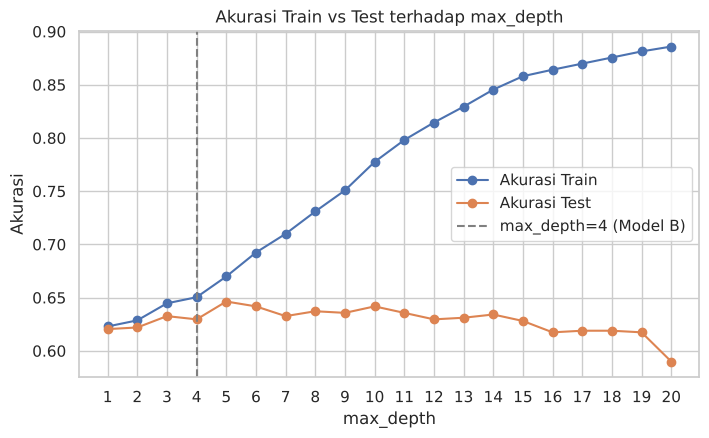

,max_depth,acc_train,acc_test
0,1,0.6229,0.6204
1,2,0.6286,0.6220
2,3,0.6447,0.6326
3,4,0.6504,0.6296
4,5,0.6698,0.6463
5,6,0.6924,0.6418
6,7,0.7099,0.6326
7,8,0.7309,0.6372
8,9,0.7508,0.6357
9,10,0.7775,0.6418


In [15]:
rows = []
for d in range(1, 21):
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    rows.append((d, m.score(X_train, y_train), m.score(X_test, y_test)))
depth_df = pd.DataFrame(rows, columns=["max_depth", "acc_train", "acc_test"])

plt.figure(figsize=(8, 4.5))
plt.plot(depth_df.max_depth, depth_df.acc_train, marker="o", label="Akurasi Train")
plt.plot(depth_df.max_depth, depth_df.acc_test, marker="o", label="Akurasi Test")
plt.axvline(4, color="gray", ls="--", label="max_depth=4 (Model B)")
plt.xlabel("max_depth"); plt.ylabel("Akurasi"); plt.xticks(range(1, 21)); plt.legend()
plt.title("Akurasi Train vs Test terhadap max_depth")
plt.savefig("../images/06_max_depth_sweep.png", dpi=150, bbox_inches="tight")
plt.show()
depth_df.round(4)

## 5. Evaluasi dan Perbandingan Model

Model A (max_depth=None)
Akurasi Train: 1.0000 | Akurasi Test: 0.5960 | Selisih: 0.4040

Classification Report (data uji):
                 precision    recall  f1-score   support

Tidak Layak (0)     0.6627    0.6875    0.6748       400
      Layak (1)     0.4813    0.4531    0.4668       256

       accuracy                         0.5960       656
      macro avg     0.5720    0.5703    0.5708       656
   weighted avg     0.5919    0.5960    0.5937       656

Confusion Matrix:
 [[275 125]
 [140 116]] 

Model B (max_depth=4)
Akurasi Train: 0.6504 | Akurasi Test: 0.6296 | Selisih: 0.0208

Classification Report (data uji):
                 precision    recall  f1-score   support

Tidak Layak (0)     0.6311    0.9450    0.7568       400
      Layak (1)     0.6140    0.1367    0.2236       256

       accuracy                         0.6296       656
      macro avg     0.6225    0.5409    0.4902       656
   weighted avg     0.6244    0.6296    0.5487       656

Confusion Matrix:
 [[37

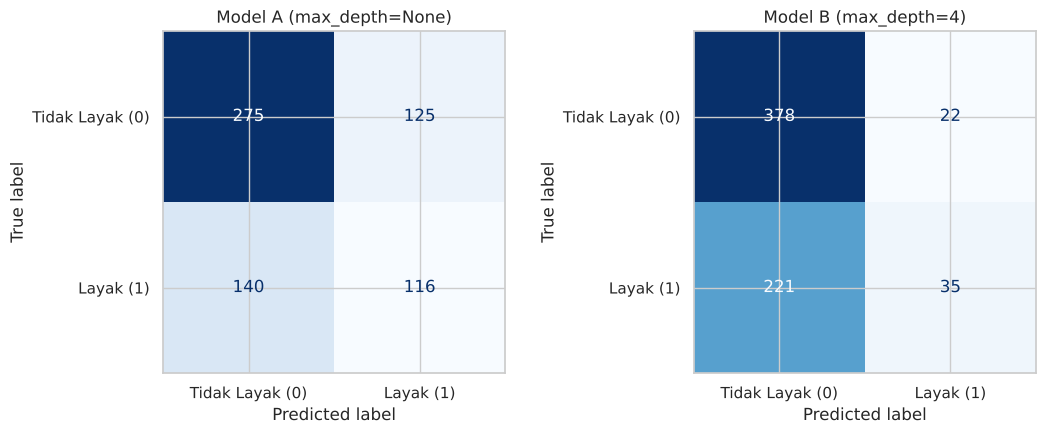

In [16]:
labels = ["Tidak Layak (0)", "Layak (1)"]
results = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (name, model) in zip(axes, {"Model A (max_depth=None)": model_a, "Model B (max_depth=4)": model_b}.items()):
    pred_test = model.predict(X_test)
    acc_tr = accuracy_score(y_train, model.predict(X_train))
    acc_te = accuracy_score(y_test, pred_test)
    results[name] = (acc_tr, acc_te)

    print("=" * 60); print(name); print("=" * 60)
    print(f"Akurasi Train: {acc_tr:.4f} | Akurasi Test: {acc_te:.4f} | Selisih: {acc_tr-acc_te:.4f}\n")
    print("Classification Report (data uji):")
    print(classification_report(y_test, pred_test, target_names=labels, digits=4))
    cm = confusion_matrix(y_test, pred_test)
    print("Confusion Matrix:\n", cm, "\n")
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.savefig("../images/07_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
cmp = pd.DataFrame(results, index=["Akurasi Train", "Akurasi Test"]).T
cmp["Gap (Train - Test)"] = cmp["Akurasi Train"] - cmp["Akurasi Test"]
cmp.round(4)

,Akurasi Train,Akurasi Test,Gap (Train - Test)
Model A (max_depth=None),1.0000,0.5960,0.4040
Model B (max_depth=4),0.6504,0.6296,0.0208


## 6. Visualisasi dan Interpretasi Model B

### 6.1 Visualisasi Pohon

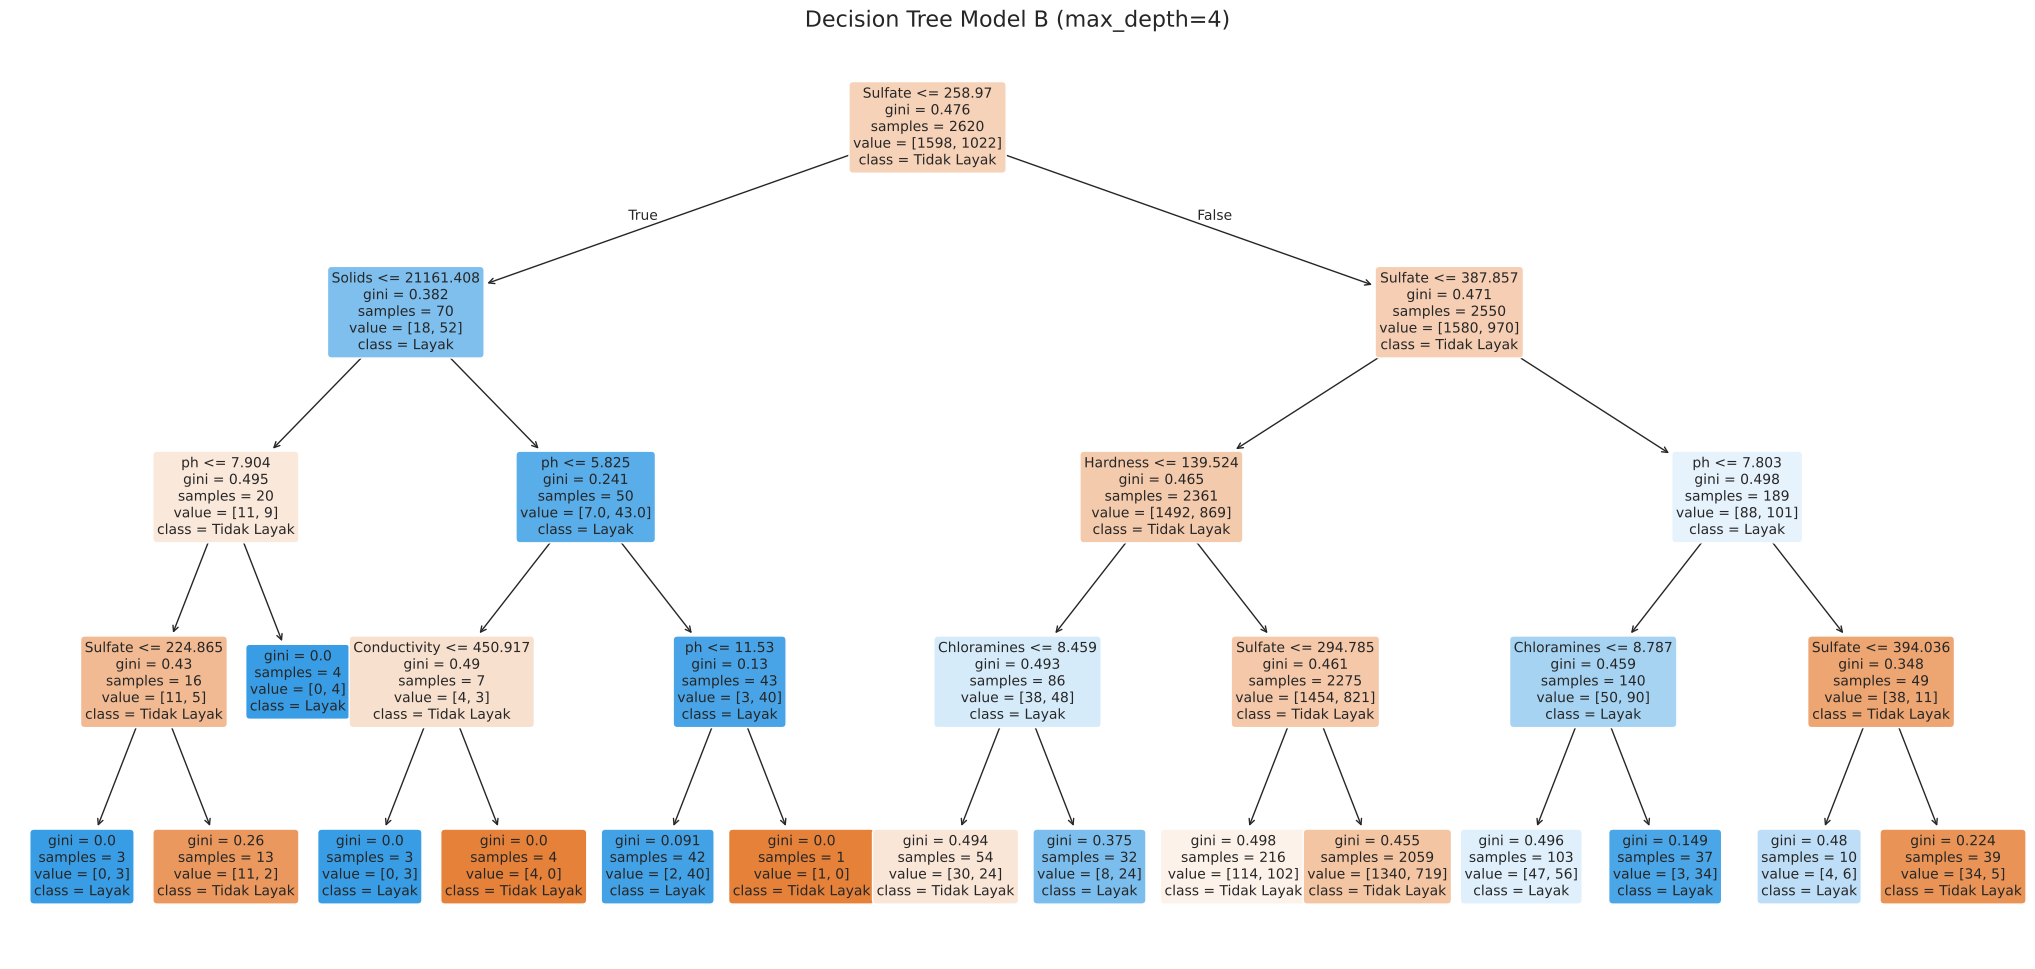

In [18]:
plt.figure(figsize=(26, 12))
plot_tree(model_b, feature_names=X_train.columns.tolist(),
          class_names=["Tidak Layak", "Layak"], filled=True, rounded=True,
          fontsize=10, proportion=False, impurity=True)
plt.title("Decision Tree Model B (max_depth=4)", fontsize=16)
plt.savefig("../images/08_decision_tree_model_b.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2 Aturan Keputusan (teks)

In [19]:
print(export_text(model_b, feature_names=X_train.columns.tolist(), show_weights=True))

|--- Sulfate <= 258.97
|   |--- Solids <= 21161.41
|   |   |--- ph <= 7.90
|   |   |   |--- Sulfate <= 224.86
|   |   |   |   |--- weights: [0.00, 3.00] class: 1
|   |   |   |--- Sulfate >  224.86
|   |   |   |   |--- weights: [11.00, 2.00] class: 0
|   |   |--- ph >  7.90
|   |   |   |--- weights: [0.00, 4.00] class: 1
|   |--- Solids >  21161.41
|   |   |--- ph <= 5.83
|   |   |   |--- Conductivity <= 450.92
|   |   |   |   |--- weights: [0.00, 3.00] class: 1
|   |   |   |--- Conductivity >  450.92
|   |   |   |   |--- weights: [4.00, 0.00] class: 0
|   |   |--- ph >  5.83
|   |   |   |--- ph <= 11.53
|   |   |   |   |--- weights: [2.00, 40.00] class: 1
|   |   |   |--- ph >  11.53
|   |   |   |   |--- weights: [1.00, 0.00] class: 0
|--- Sulfate >  258.97
|   |--- Sulfate <= 387.86
|   |   |--- Hardness <= 139.52
|   |   |   |--- Chloramines <= 8.46
|   |   |   |   |--- weights: [30.00, 24.00] class: 0
|   |   |   |--- Chloramines >  8.46
|   |   |   |   |--- weights: [8.00, 24.00] c

### 6.3 Feature Importance

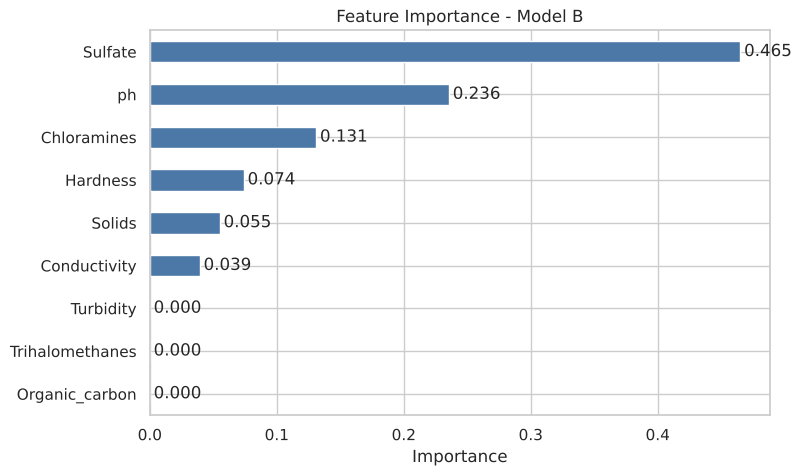

Sulfate            0.4650
ph                 0.2356
Chloramines        0.1310
Hardness           0.0740
Solids             0.0551
Conductivity       0.0393
Organic_carbon     0.0000
Trihalomethanes    0.0000
Turbidity          0.0000
dtype: float64


In [20]:
imp = pd.Series(model_b.feature_importances_, index=X_train.columns).sort_values()
plt.figure(figsize=(8, 5))
imp.plot(kind="barh", color="#4C78A8")
plt.xlabel("Importance"); plt.title("Feature Importance - Model B")
for i, v in enumerate(imp.values):
    plt.text(v + 0.003, i, f"{v:.3f}", va="center")
plt.savefig("../images/09_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(imp.sort_values(ascending=False).round(4))

## 7. Simpan Model (Joblib)

In [21]:
best_model = model_b
joblib.dump(best_model, "../model/decision_tree_model.joblib")

meta = {
    "features": X_train.columns.tolist(),
    "medians": {k: float(v) for k, v in medians.items()},
    "ranges": {c: [float(df[c].min()), float(df[c].max())] for c in X_train.columns},
    "max_depth": int(best_model.get_params()["max_depth"]),
    "accuracy_test": float(accuracy_score(y_test, best_model.predict(X_test))),
    "feature_importances": {k: float(v) for k, v in zip(X_train.columns, best_model.feature_importances_)},
}
with open("../model/model_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

# Uji muat ulang
loaded = joblib.load("../model/decision_tree_model.joblib")
sample = X_test.iloc[[0]]
print("Prediksi sampel:", loaded.predict(sample)[0], "| Label asli:", y_test.iloc[0])

Prediksi sampel: 0 | Label asli: 1


## 8. Analisis dan Interpretasi (untuk laporan)

### 8.1 Perbandingan Model A vs Model B
| Model | Akurasi Train | Akurasi Test | Gap |
|---|---|---|---|
| A (`max_depth=None`, 34 level, 536 daun) | 1.0000 | 0.5960 | 0.4040 |
| B (`max_depth=4`, 15 daun) | 0.6504 | 0.6296 | 0.0208 |

Model A **overfit**: akurasi data latih 100% (menghafal data, termasuk noise), tetapi turun tajam ke 59.6% pada data uji. Model B lebih sederhana,
akurasi uji lebih tinggi (62.96%) dan gap train-test hanya ~2%, sehingga generalisasinya jauh lebih baik. Karena itu **Model B dipilih** dan disimpan.

**Catatan kritis:** akurasi Model B masih moderat dan recall kelas "Layak" hanya 0.137 (35 dari 256 sampel layak terdeteksi). Model cenderung memprediksi
"Tidak Layak" (recall 0.945). Penyebabnya: kelas tidak seimbang (61% vs 39%) dan kedua kelas saling tumpang tindih pada fitur-fiturnya
(korelasi tiap fitur dengan target di bawah 0.04). Hasil ini sesuai dengan sifat dataset ini yang memang sulit dipisahkan; sebagai pengembangan lanjutan
dapat dicoba `class_weight="balanced"`, cross-validation, atau model ensemble (Random Forest).

### 8.2 Contoh Aturan "Jika-Maka" dari Pohon Model B
1. **JIKA** Sulfate > 258.97 **DAN** Sulfate <= 387.86 **DAN** Hardness > 139.52 **DAN** Sulfate > 294.78 **MAKA** air diprediksi **Tidak Layak Minum**
   (daun terbesar: 1340 sampel kelas 0 vs 719 kelas 1).
2. **JIKA** Sulfate <= 258.97 **DAN** Solids > 21161.41 **DAN** 5.83 < pH <= 11.53 **MAKA** air diprediksi **Layak Minum** (2 vs 40 sampel).
3. **JIKA** Sulfate > 387.86 **DAN** pH <= 7.80 **DAN** Chloramines > 8.79 **MAKA** air diprediksi **Layak Minum** (3 vs 34 sampel).

Aturan 1 mencakup mayoritas data sehingga kurang murni (35% sampelnya kelas 1), sedangkan aturan 2 dan 3 sangat murni tetapi hanya mencakup sedikit data.

### 8.3 Feature Importance
Fitur paling berpengaruh pada Model B: **Sulfate (0.465)**, **ph (0.236)**, **Chloramines (0.131)**, **Hardness (0.074)**, **Solids (0.055)**, dan **Conductivity (0.039)**.
`Organic_carbon`, `Trihalomethanes`, dan `Turbidity` bernilai 0 karena tidak dipakai pada split mana pun di pohon berkedalaman 4.
Sulfate mendominasi karena muncul di akar pohon dan beberapa percabangan lain. Importance menunjukkan kontribusi fitur pada pohon ini,
bukan hubungan sebab-akibat terhadap kelayakan air.